# Project : Legal Contract Risk Analyzer (Structured Output + Citation Checker)
**Domain:** Legal Tech / Compliance | **Level:** Intermediate | **Stack:** Python, Pydantic, Groq (gpt-oss-120b), pandas

## Problem statement
In legal work a wrong or made-up answer is dangerous. A normal chatbot writes free text and can invent clauses. In this project the LLM must return JSON in a fixed format (checked with Pydantic), and every risk it finds must come with an exact quote from the contract. I then check by code that each quote really exists in the contract. If a quote is fake, it gets removed.

## What I built
- A Pydantic schema for findings (title, risk level, quote, explanation, suggested redline)
- A retry loop: if the JSON is broken or a quote is not found, the error is sent back to the model to fix
- A citation verifier that checks every quote against the contract text
- A small evaluation: did it catch the 4 risky clause types I planted in the contract?
- Report saved as JSON and a risk chart

## Step 0: Install libraries

In [1]:
!pip install -q openai pydantic pandas matplotlib

## Step 1: Connect to Groq

In [2]:
import os, json, time, re
from getpass import getpass
from openai import OpenAI

if "GROQ_API_KEY" not in os.environ:
    os.environ["GROQ_API_KEY"] = getpass("Paste your Groq API key here: ")

client = OpenAI(api_key=os.environ["GROQ_API_KEY"], base_url="https://api.groq.com/openai/v1")
MODEL = "openai/gpt-oss-120b"

def call_llm(prompt, system="You are a helpful assistant.", json_mode=False):
    for attempt in range(3):
        try:
            msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
            if json_mode:
                res = client.chat.completions.create(model=MODEL, messages=msgs, temperature=0, response_format={"type": "json_object"})
            else:
                res = client.chat.completions.create(model=MODEL, messages=msgs, temperature=0)
            return (res.choices[0].message.content or "").strip()
        except Exception as e:
            print("LLM error (try", attempt + 1, "):", str(e)[:150])
            time.sleep(6)
    return ""

print(call_llm("Say hello in 5 words"))

Paste your Groq API key here: ··········
Hello there, nice to meet!


## Step 2: The contract
I wrote a fake vendor contract and put some unfair clauses inside on purpose (one-sided indemnity, tiny liability cap, auto renewal, vendor owning all customer data). Because I know what is planted, I can check if the AI finds them.

In [3]:
contract_text = '''MASTER SERVICES AGREEMENT
This Agreement is made between Zenith Retail Pvt Ltd ("Customer") and CloudNimbus Solutions Ltd ("Vendor").

1. Services
Vendor will provide the cloud analytics platform and support described in Schedule A. Vendor may change, suspend or discontinue any feature at any time without prior notice.

2. Fees and Payment
Customer shall pay all invoices within 15 days of the invoice date. Vendor may increase the fees at any time by giving 7 days written notice, and the increased fees apply to the current term.

3. Term and Termination
The Agreement runs for 3 years and renews automatically for further 3 year terms unless Customer gives written notice at least 180 days before the end of the term. Vendor may terminate this Agreement for convenience by giving 7 days notice. Customer may terminate only for uncured material breach and must pay all fees for the remaining term if it terminates early.

4. Indemnification
Customer shall indemnify, defend and hold harmless Vendor from any and all claims, losses, damages and expenses arising out of Customer's use of the Services, including claims caused by Vendor's own negligence. Vendor gives no indemnity to Customer of any kind.

5. Limitation of Liability
Vendor's total liability under this Agreement shall not exceed the fees paid by Customer in the one month before the claim arose. Vendor shall not be liable for any data loss, loss of profit or business interruption even if it was told such loss was possible. Customer's liability is unlimited.

6. Intellectual Property
All data uploaded by Customer, and all reports, models and other work created using the Services, shall be owned exclusively by Vendor. Customer assigns all rights in such materials to Vendor and waives any moral rights.

7. Confidentiality
Each party shall keep the other party's confidential information secret for 2 years after termination.

8. Governing Law
This Agreement is governed by the laws of Singapore and all disputes go to the courts of Singapore.'''

print("contract length:", len(contract_text), "characters")

contract length: 2017 characters


## Step 3: Schema with Pydantic
This is the fixed format the AI has to follow. If the JSON does not match, Pydantic throws an error and I can catch it.

In [4]:
from pydantic import BaseModel, Field
from typing import List, Optional, Literal

class Finding(BaseModel):
    clause_title: str
    risk_level: Literal["LOW", "MEDIUM", "HIGH", "CRITICAL"]
    verbatim_quote: str = Field(description="exact text copied from the contract")
    risk_explanation: str
    suggested_redline: Optional[str] = None

class ContractReport(BaseModel):
    contract_type: str
    overall_risk_score: int = Field(description="1 to 100, higher is riskier")
    findings: List[Finding]

schema_text = json.dumps(ContractReport.model_json_schema())
print("schema ready, length:", len(schema_text))

schema ready, length: 1031


## Step 4: Analyze with a retry loop + citation check
Steps in the loop:
1. Ask the model for JSON
2. Validate with Pydantic (if it fails, send the error back and retry)
3. Check every `verbatim_quote` exists in the contract (spaces are normalized first)
4. If some quotes are fake, tell the model which ones and retry
5. After 3 tries, keep only the verified findings and count how many were removed

In [5]:
def clean(text):
    return " ".join(text.split())

system_prompt = "You are a careful contract lawyer. You find risky clauses for the Customer. You must copy quotes exactly from the contract, never paraphrase."

def analyze_contract(contract, max_tries=3):
    error_note = ""
    best_good = []
    best_report = None
    removed = 0
    tries_used = 0

    for attempt in range(1, max_tries + 1):
        tries_used = attempt
        prompt = "Analyze this contract and return ONLY JSON that matches this JSON schema:\n" + schema_text
        prompt = prompt + "\n\nFor each risky clause give a verbatim_quote copied exactly from the contract. Cover indemnity, liability, termination, IP and anything else risky."
        prompt = prompt + "\n\nCONTRACT:\n" + contract + error_note

        raw = call_llm(prompt, system_prompt, json_mode=True)
        raw = re.sub(r"^```json|^```|```$", "", raw.strip(), flags=re.M).strip()

        try:
            report = ContractReport.model_validate_json(raw)
        except Exception as e:
            print("attempt", attempt, "- JSON not valid:", str(e)[:120])
            error_note = "\n\nYour last answer failed validation: " + str(e)[:300] + " Fix it and return only JSON."
            continue

        good = []
        bad = []
        for f in report.findings:
            if clean(f.verbatim_quote) in clean(contract):
                good.append(f)
            else:
                bad.append(f)

        print("attempt", attempt, "- findings:", len(report.findings), "| verified quotes:", len(good), "| fake quotes:", len(bad))

        if len(good) >= len(best_good):
            best_good = good
            best_report = report
            removed = len(bad)

        if len(bad) == 0:
            break

        error_note = "\n\nThese quotes were NOT found exactly in the contract, copy them exactly this time:\n"
        for b in bad:
            error_note = error_note + "- " + b.verbatim_quote[:150] + "\n"

    if best_report is None:
        return None, 0, tries_used

    best_report.findings = best_good
    return best_report, removed, tries_used

report, removed_count, tries_used = analyze_contract(contract_text)
print("\ntries used:", tries_used)
print("fake citations removed:", removed_count)

attempt 1 - findings: 6 | verified quotes: 6 | fake quotes: 0

tries used: 1
fake citations removed: 0


## Step 5: See the findings

In [6]:
import pandas as pd

order = {"CRITICAL": 4, "HIGH": 3, "MEDIUM": 2, "LOW": 1}

rows = []
for f in report.findings:
    rows.append({
        "clause": f.clause_title,
        "risk": f.risk_level,
        "quote": f.verbatim_quote[:90] + "...",
        "why_risky": f.risk_explanation[:110] + "...",
    })

findings_df = pd.DataFrame(rows)
findings_df["rank"] = findings_df["risk"].map(order)
findings_df = findings_df.sort_values("rank", ascending=False).drop(columns="rank")

print("Contract type:", report.contract_type)
print("Overall risk score:", report.overall_risk_score, "/ 100")
print("Total verified findings:", len(findings_df))
findings_df

Contract type: Master Services Agreement
Overall risk score: 80 / 100
Total verified findings: 6


,clause,risk,quote,why_risky
1,Limitation of Liability,CRITICAL,Vendor's total liability under this Agreement ...,Vendor's liability cap is extremely low and ex...
0,Indemnification,HIGH,"Customer shall indemnify, defend and hold harm...",The clause places the entire indemnity burden ...
2,Termination,HIGH,Vendor may terminate this Agreement for conven...,Termination rights are heavily skewed to the V...
3,Intellectual Property,HIGH,"All data uploaded by Customer, and all reports...",The clause strips the Customer of ownership of...
4,Fees and Payment,MEDIUM,Vendor may increase the fees at any time by gi...,Vendor can raise fees unilaterally with only a...
5,Services,MEDIUM,"Vendor may change, suspend or discontinue any ...",The Vendor retains the right to alter or disco...


In [7]:
print("Example finding in full:\n")
top = sorted(report.findings, key=lambda x: order[x.risk_level], reverse=True)[0]
print("Clause  :", top.clause_title)
print("Risk    :", top.risk_level)
print("Quote   :", top.verbatim_quote)
print("Why     :", top.risk_explanation)
print("Redline :", top.suggested_redline)

Example finding in full:

Clause  : Limitation of Liability
Risk    : CRITICAL
Quote   : Vendor's total liability under this Agreement shall not exceed the fees paid by Customer in the one month before the claim arose. Vendor shall not be liable for any data loss, loss of profit or business interruption even if it was told such loss was possible. Customer's liability is unlimited.
Why     : Vendor's liability cap is extremely low and excludes core damages such as data loss and business interruption, while the Customer has unlimited liability. This asymmetry leaves the Customer exposed to potentially catastrophic losses with minimal recourse.
Redline : Limit Vendor's liability to at least the total fees paid in the preceding 12 months and include liability for data loss, loss of profit, and business interruption caused by Vendor's negligence. Remove unlimited liability for Customer.


## Step 6: Check against the planted risks
I planted 4 types of risky clause. Here I check if at least one finding covers each type (by looking at title and quote text).

In [8]:
planted = {
    "Indemnification": ["indemn"],
    "Limitation of Liability": ["liabilit"],
    "Termination / Auto-renewal": ["terminat", "renew"],
    "IP Assignment": ["intellectual", "ownership", "assign", "owned"],
}

caught = 0
for name, words in planted.items():
    found = False
    for f in report.findings:
        text = (f.clause_title + " " + f.verbatim_quote).lower()
        for w in words:
            if w in text:
                found = True
    print(name, "->", "CAUGHT" if found else "MISSED")
    if found:
        caught = caught + 1

print("\nplanted risks caught:", caught, "/", len(planted))

Indemnification -> CAUGHT
Limitation of Liability -> CAUGHT
Termination / Auto-renewal -> CAUGHT
IP Assignment -> CAUGHT

planted risks caught: 4 / 4


## Step 7: Risk chart + save report

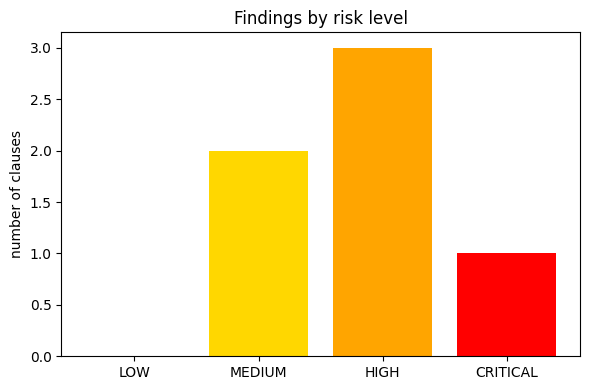

saved contract_report.json


In [9]:
import matplotlib.pyplot as plt

counts = {"LOW": 0, "MEDIUM": 0, "HIGH": 0, "CRITICAL": 0}
for f in report.findings:
    counts[f.risk_level] = counts[f.risk_level] + 1

plt.figure(figsize=(6, 4))
plt.bar(list(counts.keys()), list(counts.values()), color=["green", "gold", "orange", "red"])
plt.title("Findings by risk level")
plt.ylabel("number of clauses")
plt.tight_layout()
plt.savefig("risk_levels.png")
plt.show()

with open("contract_report.json", "w") as file:
    file.write(report.model_dump_json(indent=2))
print("saved contract_report.json")

## Step 8: Results summary

In [10]:
total_quotes = len(report.findings) + removed_count
print("Findings kept (all quotes verified):", len(report.findings))
print("Fake quotes caught and removed:", removed_count, "out of", total_quotes)
print("Planted risks caught:", caught, "/", len(planted))
print("Attempts needed:", tries_used)
print()
print("Resume bullet (from my own run):")
print("Built a legal contract risk analyzer using Pydantic-validated JSON output and an automatic citation checker; it caught", caught, "of", len(planted), "planted risky clauses and removed", removed_count, "unverifiable quotes so every reported finding points to real contract text.")

Findings kept (all quotes verified): 6
Fake quotes caught and removed: 0 out of 6
Planted risks caught: 4 / 4
Attempts needed: 1

Resume bullet (from my own run):
Built a legal contract risk analyzer using Pydantic-validated JSON output and an automatic citation checker; it caught 4 of 4 planted risky clauses and removed 0 unverifiable quotes so every reported finding points to real contract text.


## Key learnings
- Asking for JSON is not enough, you need Pydantic to validate it and a retry loop when it fails
- The citation check is simple (substring match) but very powerful, it stops fake quotes completely
- Normalizing spaces before matching matters, otherwise line breaks cause false "fake" quotes
- For legal or finance use cases you should always show the source text next to the answer

## Skills shown
Pydantic, Structured LLM output, Prompt engineering, Retry / self-correction loops, Automated fact-checking, Legal-tech use case, Groq API

## Ideas to extend
- Read real contracts from PDF
- Add a clause-type classifier before analysis
- Build a Streamlit page that highlights the quotes inside the contract

Note: this is a learning project, not legal advice.

---
**Built by Akshat Kesharwani** | Portfolio: https://akshatkesharwani-info.github.io/ | GitHub: https://github.com/akshatkesharwani-info

Project idea taken from the Dipanshu.Decoded Agentic AI handbook. I rewrote the code to run free on Groq and added my own test questions and evaluation.